In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../data/banking.csv")

print("Размер датасета:", df.shape)
print("\nНазвания столбцов:")
print(df.columns.tolist())

df.head()

Размер датасета: (41188, 21)

Названия столбцов:
['age', 'job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'emp_var_rate', 'cons_price_idx', 'cons_conf_idx', 'euribor3m', 'nr_employed', 'y']


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp_var_rate,cons_price_idx,cons_conf_idx,euribor3m,nr_employed,y
0,44,blue-collar,married,basic.4y,unknown,yes,no,cellular,aug,thu,...,1,999,0,nonexistent,1.4,93.444,-36.1,4.963,5228.1,0
1,53,technician,married,unknown,no,no,no,cellular,nov,fri,...,1,999,0,nonexistent,-0.1,93.200,-42.0,4.021,5195.8,0
2,28,management,single,university.degree,no,yes,no,cellular,jun,thu,...,3,6,2,success,-1.7,94.055,-39.8,0.729,4991.6,1
3,39,services,married,high.school,no,no,no,cellular,apr,fri,...,2,999,0,nonexistent,-1.8,93.075,-47.1,1.405,5099.1,0
4,55,retired,married,basic.4y,no,yes,no,cellular,aug,fri,...,1,3,1,success,-2.9,92.201,-31.4,0.869,5076.2,1


Типы данных:
age                 int64
job                   str
marital               str
education             str
default               str
housing               str
loan                  str
contact               str
month                 str
day_of_week           str
duration            int64
campaign            int64
pdays               int64
previous            int64
poutcome              str
emp_var_rate      float64
cons_price_idx    float64
cons_conf_idx     float64
euribor3m         float64
nr_employed       float64
y                   int64
dtype: object

Пропущенные значения:
0

Количество клиентов по классам:
y
0    36548
1     4640
Name: count, dtype: int64

Доля каждого класса:
y
0    0.887
1    0.113
Name: proportion, dtype: float64


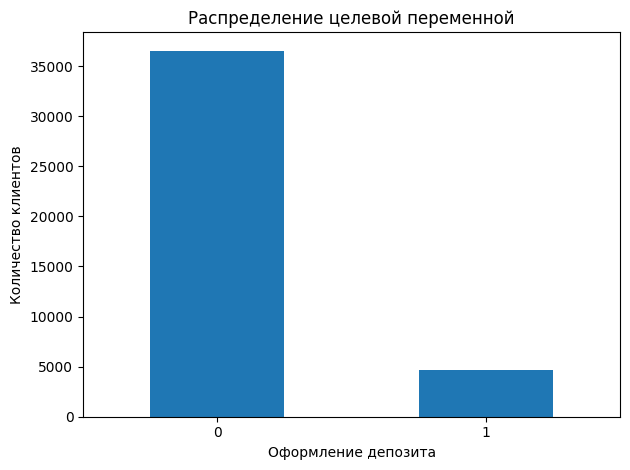

In [3]:
# Проверяем типы данных
print("Типы данных:")
print(df.dtypes)

# Проверяем пропущенные значения
print("\nПропущенные значения:")
print(df.isnull().sum().sum())

# Проверяем распределение целевого класса
print("\nКоличество клиентов по классам:")
print(df["y"].value_counts())

print("\nДоля каждого класса:")
print(df["y"].value_counts(normalize=True).round(3))

# Строим график баланса классов
df["y"].value_counts().plot(kind="bar")

plt.title("Распределение целевой переменной")
plt.xlabel("Оформление депозита")
plt.ylabel("Количество клиентов")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression

# Разделяем признаки и целевую переменную
X = df.drop(columns=["y"])
y = df["y"]

# Определяем числовые и категориальные признаки
numeric_features = X.select_dtypes(include=["int64", "float64"]).columns
categorical_features = X.select_dtypes(include=["str", "object", "category"]).columns

# Делим данные на обучающую и тестовую выборки
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Размер обучающей выборки:", X_train.shape)
print("Размер тестовой выборки:", X_test.shape)
print("\nЧисловых признаков:", len(numeric_features))
print("Категориальных признаков:", len(categorical_features))

Размер обучающей выборки: (32950, 20)
Размер тестовой выборки: (8238, 20)

Числовых признаков: 10
Категориальных признаков: 10


In [5]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression

# Подготовка числовых признаков
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Подготовка категориальных признаков
categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Объединяем предобработку
preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

# Создаём общий пайплайн
model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

# Обучаем модель
model.fit(X_train, y_train)

print("Модель успешно обучена!")

Модель успешно обучена!


In [6]:
from sklearn.metrics import (
    roc_curve,
    roc_auc_score,
    precision_recall_curve,
    average_precision_score
)

# Получаем вероятность того, что клиент оформит депозит
y_proba = model.predict_proba(X_test)[:, 1]

# Рассчитываем ROC-AUC
roc_auc = roc_auc_score(y_test, y_proba)

# Рассчитываем PR-кривую и Average Precision
precision_values, recall_values, pr_thresholds = precision_recall_curve(
    y_test, y_proba
)
pr_auc = average_precision_score(y_test, y_proba)

print("ROC-AUC:", round(roc_auc, 3))
print("PR-AUC (Average Precision):", round(pr_auc, 3))

ROC-AUC: 0.938
PR-AUC (Average Precision): 0.599


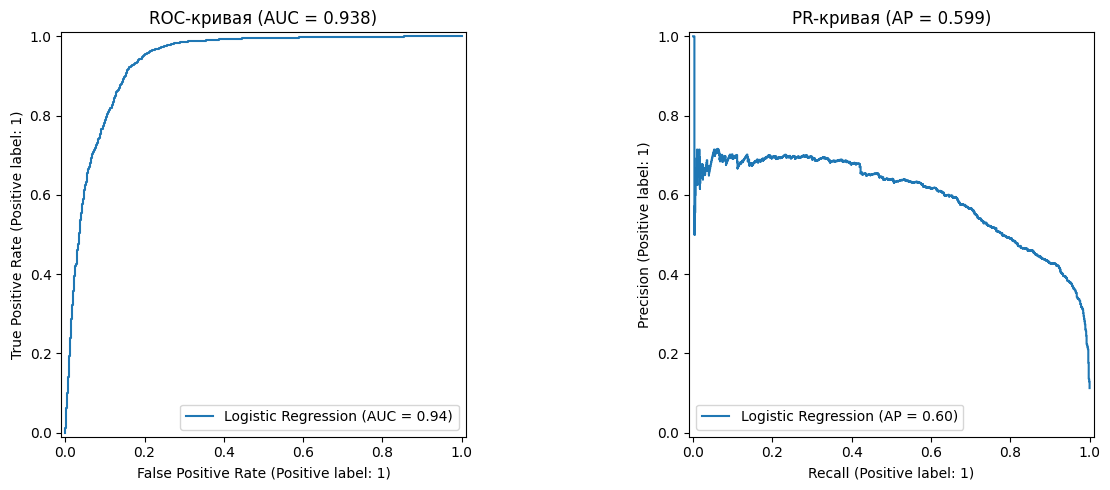

In [7]:
from sklearn.metrics import RocCurveDisplay, PrecisionRecallDisplay

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# ROC-кривая
RocCurveDisplay.from_predictions(
    y_test, y_proba, ax=axes[0], name="Logistic Regression"
)
axes[0].set_title(f"ROC-кривая (AUC = {roc_auc:.3f})")

# PR-кривая
PrecisionRecallDisplay.from_predictions(
    y_test, y_proba, ax=axes[1], name="Logistic Regression"
)
axes[1].set_title(f"PR-кривая (AP = {pr_auc:.3f})")

plt.tight_layout()
plt.show()

In [8]:
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score

# Предсказания при стандартном пороге 0.5
y_pred_default = (y_proba >= 0.5).astype(int)

# Проверяем разные пороги и выбираем тот,
# который даёт минимальную стоимость ошибок
thresholds = np.arange(0.05, 0.51, 0.01)

results = []

for threshold in thresholds:
    y_pred = (y_proba >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()

    cost = 3 * fn + fp

    results.append({
        "threshold": threshold,
        "FP": fp,
        "FN": fn,
        "cost": cost,
        "precision": precision_score(y_test, y_pred, zero_division=0),
        "recall": recall_score(y_test, y_pred, zero_division=0),
        "F1": f1_score(y_test, y_pred, zero_division=0)
    })

results_df = pd.DataFrame(results)

best_result = results_df.loc[results_df["cost"].idxmin()]
best_threshold = best_result["threshold"]

print("Стандартный порог: 0.50")
print("Выбранный порог:", round(best_threshold, 2))
print("\nРезультаты для выбранного порога:")
print(best_result)

Стандартный порог: 0.50
Выбранный порог: 0.2

Результаты для выбранного порога:
threshold       0.200000
FP            664.000000
FN            220.000000
cost         1324.000000
precision       0.516035
recall          0.762931
F1              0.615652
Name: 15, dtype: float64


In [9]:
# Функция для расчёта метрик и стоимости ошибок
def evaluate_threshold(y_true, y_prob, threshold):
    y_pred = (y_prob >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()

    return {
        "Порог": threshold,
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp,
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1": f1_score(y_true, y_pred, zero_division=0),
        "Стоимость ошибок": 3 * fn + fp
    }

comparison = pd.DataFrame([
    evaluate_threshold(y_test, y_proba, 0.5),
    evaluate_threshold(y_test, y_proba, best_threshold)
])

comparison.round(3)

,Порог,TN,FP,FN,TP,Precision,Recall,F1,Стоимость ошибок
0,0.5,7126,184,540,388,0.678,0.418,0.517,1804
1,0.2,6646,664,220,708,0.516,0.763,0.616,1324


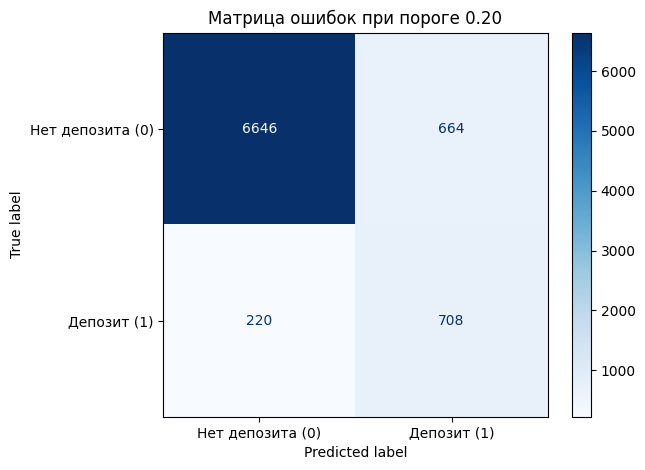

In [10]:
from sklearn.metrics import ConfusionMatrixDisplay

# Предсказания с выбранным порогом
y_pred_best = (y_proba >= best_threshold).astype(int)

# Строим матрицу ошибок
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_best,
    display_labels=["Нет депозита (0)", "Депозит (1)"],
    cmap="Blues",
    values_format="d"
)

plt.title(f"Матрица ошибок при пороге {best_threshold:.2f}")
plt.tight_layout()
plt.show()

### Анализ матрицы ошибок

При выбранном пороге 0.20 модель правильно определила 6646 клиентов, которые не оформили депозит (TN), и 708 клиентов, которые оформили депозит (TP).

При этом 664 клиента были ошибочно отнесены к заинтересованным в депозите (FP), а 220 потенциальных вкладчиков модель не выявила (FN).

Поскольку в нашей задаче пропустить потенциального клиента считается в три раза дороже, чем ошибочно заинтересоваться клиентом, был выбран порог 0.20 вместо стандартного 0.50. При этом пороге Recall вырос с 0.418 до 0.763, F1 — с 0.517 до 0.616, а условная стоимость ошибок снизилась с 1804 до 1324 единиц.